In [11]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
import matplotlib.pyplot as plt

In [12]:
df = sns.load_dataset('penguins').dropna()

In [13]:
df_binary = df[df['species'].isin(['Adelie', 'Gentoo'])].copy()

In [14]:
df_binary['target'] = df_binary['species'].apply(lambda x: 1 if x == 'Adelie' else 0)

In [15]:
X = df_binary[['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']].values.astype(np.float32)
y = df_binary['target'].values.astype(np.float32)

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [17]:
scaler = StandardScaler()
X_train_norm = scaler.fit_transform(X_train)
X_test_norm = scaler.transform(X_test)

In [18]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),
    tf.keras.layers.Dense(units=1, activation="sigmoid")
])

In [19]:
model.compile(
    loss="binary_crossentropy",
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    metrics=["accuracy"]
)

In [20]:
history = model.fit(X_train_norm, y_train, epochs=1000)

Epoch 1/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.1651 - loss: 0.8890
Epoch 2/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.2358 - loss: 0.8231 
Epoch 3/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3349 - loss: 0.7639 
Epoch 4/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4528 - loss: 0.7106 
Epoch 5/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5991 - loss: 0.6628 
Epoch 6/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7406 - loss: 0.6198 
Epoch 7/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8019 - loss: 0.5811 
Epoch 8/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8585 - loss: 0.5462 
Epoch 9/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9009 - loss: 0.5148 
Epoch 10/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9434 - loss: 0.4863 
Epoch 11/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9575 - loss: 0.4604 
Epoch 12/1000
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 

In [21]:
y_predict = model.predict(X_test_norm) > 0.5

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


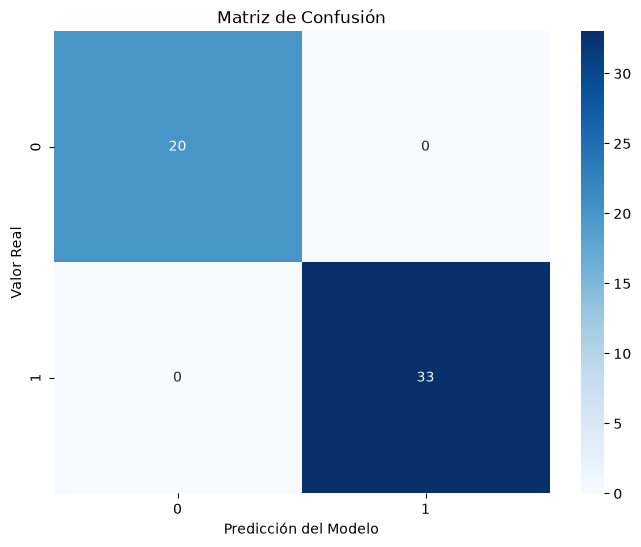

In [22]:
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_confusion, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.title('Matriz de Confusión')
plt.show()